# DCMC-Fusion: Model-centric Analysis

## Objective

Evaluate how the **choice of fusion classifier** (Logistic Regression, Random Forest, SVM, or XGBoost) affects F1-macro across the same architectural combinations and values of $K$ used in the data-centric analysis.

## Required input files

Place these five CSV files **directly in `/content/`** in Google Colab:

| File | $K$ | Datasets | Evaluations (4 classifiers per dataset) |
|---|---:|---:|---:|
| `global_metrics_k1.csv` | 1 | 5 | 20 |
| `global_metrics_k2.csv` | 2 | 10 | 40 |
| `global_metrics_k3.csv` | 3 | 10 | 40 |
| `global_metrics_k4.csv` | 4 | 5 | 20 |
| `global_metrics_k5.csv` | 5 | 1 | 4 |
| **Total** | | **31** | **124** |

Each CSV must contain `K`, `architectures`, `classifier`, and `f1_macro`. The same 124 previously generated evaluations are reused: **no models are retrained**.

## Visualization

The figure has **four panels**, one per fixed classifier. Each panel contains **31 blue circles** (one F1-macro per architectural combination, grouped by $K$) and **five orange diamonds** (mean F1-macro across the datasets at each $K$). Each blue circle corresponds to **one experimental configuration**, not the average of four classifiers. A diamond aggregates 5, 10, 10, 5, or 1 configurations for $K=1,2,3,4,5$ respectively. The panels share the same vertical scale to facilitate comparison.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('/content')
OUTPUT_DIR = DATA_DIR / 'model_centric_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_DATASETS = {1: 5, 2: 10, 3: 10, 4: 5, 5: 1}
CLASSIFIERS = ['Logistic Regression', 'Random Forest', 'SVM', 'XGBoost']
EXPECTED_CLASSIFIERS = set(CLASSIFIERS)


## 1. Load and validate the five CSV files

In [2]:
files = [DATA_DIR / f'global_metrics_k{k}.csv' for k in range(1, 6)]
missing_files = [str(path) for path in files if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f'Missing files in {DATA_DIR}: {missing_files}')

results = pd.concat([pd.read_csv(path) for path in files], ignore_index=True)
required = {'K', 'architectures', 'classifier', 'f1_macro'}
missing_columns = required - set(results.columns)
if missing_columns:
    raise ValueError(f'Missing columns: {sorted(missing_columns)}')

if len(results) != 124:
    raise ValueError(f'Expected 124 evaluations; found {len(results)}')
if results['f1_macro'].isna().any() or not results['f1_macro'].between(0, 1).all():
    raise ValueError('F1-macro must be non-null and between 0 and 1')
if set(results['K']) != set(EXPECTED_DATASETS):
    raise ValueError(f'Unexpected K values: {sorted(results["K"].unique())}')

for (k, arch), group in results.groupby(['K', 'architectures']):
    if len(group) != 4 or set(group['classifier']) != EXPECTED_CLASSIFIERS or group['classifier'].duplicated().any():
        raise ValueError(f'Unexpected classifiers or duplicates for K={k}, {arch}')
counts = results.groupby('K')['architectures'].nunique().to_dict()
if counts != EXPECTED_DATASETS:
    raise ValueError(f'Unexpected datasets per K: {counts}')

print(f'Validated {len(results)} evaluations across {sum(counts.values())} datasets')
display(results.head())


Validated 124 evaluations across 31 datasets


,K,architectures,classifier,accuracy,precision_macro,recall_macro,f1_macro
0,1,resnet50,Logistic Regression,0.656836,0.658851,0.656836,0.655745
1,1,resnet50,Random Forest,0.691689,0.710685,0.691689,0.684579
2,1,resnet50,XGBoost,0.693029,0.707031,0.693029,0.687750
3,1,resnet50,SVM,0.684987,0.707556,0.684987,0.676184
4,1,densenet121,Logistic Regression,0.655496,0.655506,0.655496,0.655490


## 2. Summarize performance for each fixed classifier and K

Within each classifier, the mean is computed across architectural combinations at the same $K$. The standard deviation measures variation **between combinations**, not cross-validation uncertainty. It is undefined for $K=5$ because there is only one dataset.

In [3]:
summary = (results.groupby(['classifier', 'K'], as_index=False)
           .agg(datasets=('f1_macro', 'size'),
                mean_f1=('f1_macro', 'mean'),
                std_f1=('f1_macro', 'std'),
                min_f1=('f1_macro', 'min'),
                max_f1=('f1_macro', 'max')))
summary['classifier'] = pd.Categorical(summary['classifier'], categories=CLASSIFIERS, ordered=True)
summary = summary.sort_values(['classifier', 'K']).reset_index(drop=True)
summary.to_csv(OUTPUT_DIR / 'model_centric_summary.csv', index=False)
results.sort_values(['classifier', 'K', 'architectures']).to_csv(OUTPUT_DIR / 'model_centric_points.csv', index=False)
display(summary)


,classifier,K,datasets,mean_f1,std_f1,min_f1,max_f1
0,Logistic Regression,1,5,0.648893,0.042261,0.579225,0.694604
1,Logistic Regression,2,10,0.679062,0.016271,0.652710,0.701737
2,Logistic Regression,3,10,0.687969,0.011077,0.670232,0.701953
3,Logistic Regression,4,5,0.698062,0.008016,0.687420,0.707226
4,Logistic Regression,5,1,0.706415,NaN,0.706415,0.706415
5,Random Forest,1,5,0.679993,0.016885,0.660119,0.696688
6,Random Forest,2,10,0.699690,0.008560,0.681989,0.713479
7,Random Forest,3,10,0.702219,0.005699,0.691967,0.712791
8,Random Forest,4,5,0.704327,0.003375,0.702471,0.710336
9,Random Forest,5,1,0.702822,NaN,0.702822,0.702822


## 3. Visualize F1-macro by classifier and K

Each panel keeps the classifier fixed; the blue circles show individual architectural combinations, and orange diamonds show the mean for each $K$.

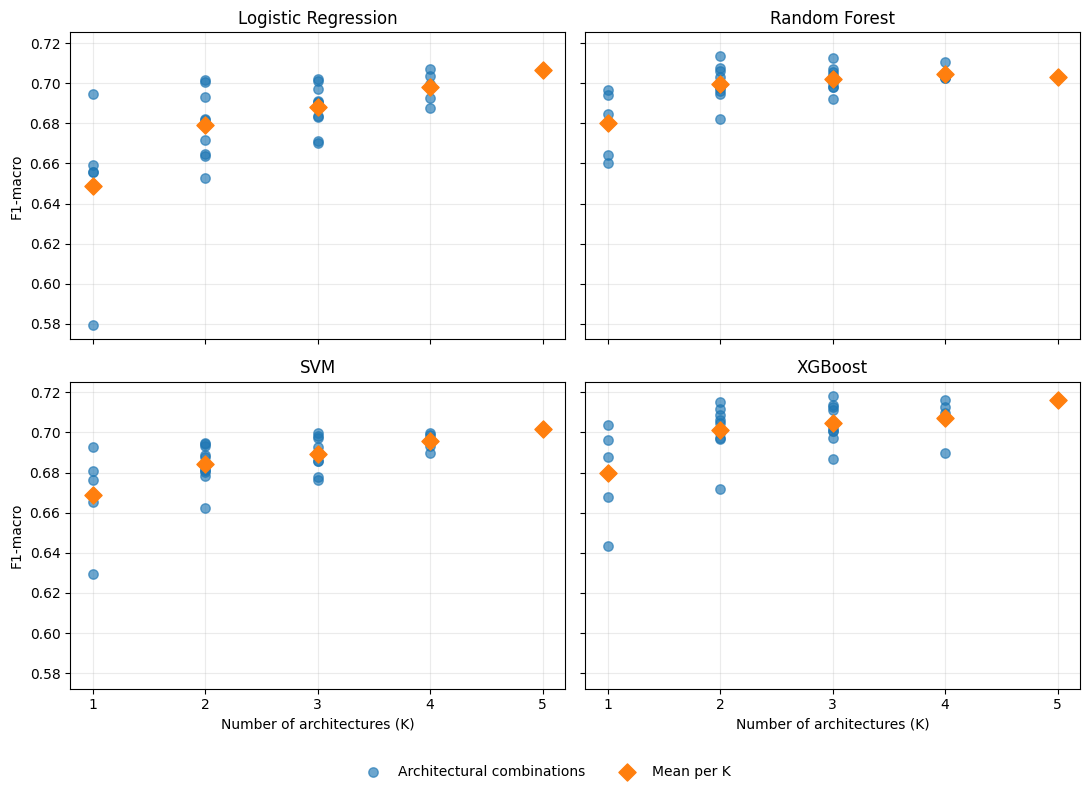

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)

for ax, classifier in zip(axes.flat, CLASSIFIERS):
    subset = results.loc[results['classifier'] == classifier]
    means = summary.loc[summary['classifier'] == classifier]
    ax.scatter(subset['K'], subset['f1_macro'], s=46, alpha=0.65,
               color='tab:blue', label='Architectural combinations', zorder=2)
    ax.scatter(means['K'], means['mean_f1'], marker='D', s=76,
               color='tab:orange', label='Mean per K', zorder=3)
    ax.set_title(classifier)
    ax.set_xticks(range(1, 6))
    ax.grid(alpha=0.25)

for ax in axes[1, :]:
    ax.set_xlabel('Number of architectures (K)')
for ax in axes[:, 0]:
    ax.set_ylabel('F1-macro')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False,
           bbox_to_anchor=(0.5, 0.005))
fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(OUTPUT_DIR / 'model_centric_scatter.png', dpi=300, bbox_inches='tight')
fig.savefig(OUTPUT_DIR / 'model_centric_scatter.pdf', bbox_inches='tight')
plt.show()


## 4. Compare classifiers using the same datasets

The following table shows the mean F1-macro of each classifier at each $K$. It is descriptive; a higher average does not establish statistical significance.

In [5]:
comparison = summary.pivot(index='K', columns='classifier', values='mean_f1')
comparison = comparison[CLASSIFIERS]
comparison.to_csv(OUTPUT_DIR / 'model_centric_comparison.csv')
display(comparison.round(4))
print(f'Outputs saved to: {OUTPUT_DIR}')


classifier,Logistic Regression,Random Forest,SVM,XGBoost
K,,,,
1,0.6489,0.6800,0.6689,0.6798
2,0.6791,0.6997,0.6842,0.7012
3,0.6880,0.7022,0.6892,0.7048
4,0.6981,0.7043,0.6958,0.7070
5,0.7064,0.7028,0.7019,0.7160


Outputs saved to: /content/model_centric_results
